Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset dimensions: (500000, 24)


,FlightDate,Day_Of_Week,Airline,Tail_Number,Dep_Airport,Dep_CityName,DepTime_label,Dep_Delay,Dep_Delay_Tag,Dep_Delay_Type,...,Flight_Duration,Distance_type,Delay_Carrier,Delay_Weather,Delay_NAS,Delay_Security,Delay_LastAircraft,Manufacturer,Model,Aicraft_age
0,2023-01-02,1,Endeavor Air,N605LR,BDL,"Hartford, CT",Morning,-3,0,Low <5min,...,56,Short Haul >1500Mi,0,0,0,0,0,CANADAIR REGIONAL JET,CRJ,16
1,2023-01-03,2,Endeavor Air,N605LR,BDL,"Hartford, CT",Morning,-5,0,Low <5min,...,62,Short Haul >1500Mi,0,0,0,0,0,CANADAIR REGIONAL JET,CRJ,16
2,2023-01-04,3,Endeavor Air,N331PQ,BDL,"Hartford, CT",Morning,-5,0,Low <5min,...,49,Short Haul >1500Mi,0,0,0,0,0,CANADAIR REGIONAL JET,CRJ,10
3,2023-01-05,4,Endeavor Air,N906XJ,BDL,"Hartford, CT",Morning,-6,0,Low <5min,...,54,Short Haul >1500Mi,0,0,0,0,0,CANADAIR REGIONAL JET,CRJ,17
4,2023-01-06,5,Endeavor Air,N337PQ,BDL,"Hartford, CT",Morning,-1,0,Low <5min,...,50,Short Haul >1500Mi,0,0,0,0,0,CANADAIR REGIONAL JET,CRJ,10


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 24 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   FlightDate          500000 non-null  object
 1   Day_Of_Week         500000 non-null  int64 
 2   Airline             500000 non-null  object
 3   Tail_Number         500000 non-null  object
 4   Dep_Airport         500000 non-null  object
 5   Dep_CityName        500000 non-null  object
 6   DepTime_label       500000 non-null  object
 7   Dep_Delay           500000 non-null  int64 
 8   Dep_Delay_Tag       500000 non-null  int64 
 9   Dep_Delay_Type      500000 non-null  object
 10  Arr_Airport         500000 non-null  object
 11  Arr_CityName        500000 non-null  object
 12  Arr_Delay           500000 non-null  int64 
 13  Arr_Delay_Type      500000 non-null  object
 14  Flight_Duration     500000 non-null  int64 
 15  Distance_type       500000 non-null  object
 16  De

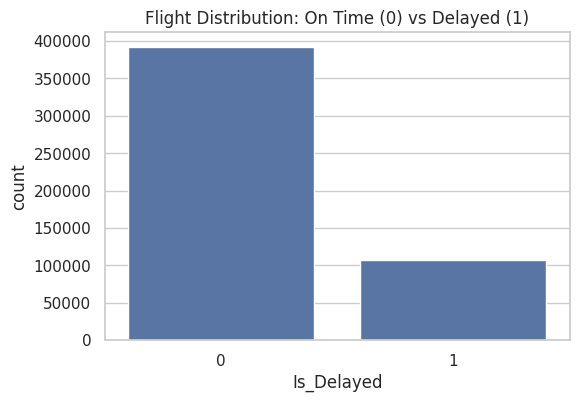

In [ ]:
from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Flight_Delay_Prediction/US_flights_2023.csv'

df = pd.read_csv(file_path, nrows=500000)

print("Dataset dimensions:", df.shape)

display(df.head())

df.info()

delay_column = 'Arr_Delay'

df = df.dropna(subset=[delay_column])

df['Is_Delayed'] = (df[delay_column] > 15).astype(int)

print("\nTarget variable distribution:")

print(df['Is_Delayed'].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Is_Delayed')
plt.title('Flight Distribution: On Time (0) vs Delayed (1)')
plt.show()

In [ ]:
columns_to_drop = [
    'Arr_Delay', 'Dep_Delay', 'Dep_Delay_Tag', 'Dep_Delay_Type',
    'Arr_Delay_Type', 'Delay_Carrier', 'Delay_Weather', 'Delay_NAS',
    'Delay_Security', 'Delay_LastAircraft',
    'Tail_Number', 'FlightDate',
    'Dep_CityName', 'Arr_CityName'
]

df_clean = df.drop(columns=columns_to_drop)

df_clean = df_clean.dropna()

print("Dataset dimensions after cleaning (no data leakage or missing values):", df_clean.shape)

categorical_cols = df_clean.select_dtypes(include=['object']).columns.tolist()
numeric_cols = df_clean.select_dtypes(exclude=['object']).columns.tolist()

print("\nCategorical variables requiring encoding:", categorical_cols)
print("Numerical variables:", numeric_cols)

display(df_clean.head())

Dataset dimensions after cleaning (no data leakage or missing values): (500000, 11)

Categorical variables requiring encoding: ['Airline', 'Dep_Airport', 'DepTime_label', 'Arr_Airport', 'Distance_type', 'Manufacturer', 'Model']
Numerical variables: ['Day_Of_Week', 'Flight_Duration', 'Aicraft_age', 'Is_Delayed']


,Day_Of_Week,Airline,Dep_Airport,DepTime_label,Arr_Airport,Flight_Duration,Distance_type,Manufacturer,Model,Aicraft_age,Is_Delayed
0,1,Endeavor Air,BDL,Morning,LGA,56,Short Haul >1500Mi,CANADAIR REGIONAL JET,CRJ,16,0
1,2,Endeavor Air,BDL,Morning,LGA,62,Short Haul >1500Mi,CANADAIR REGIONAL JET,CRJ,16,0
2,3,Endeavor Air,BDL,Morning,LGA,49,Short Haul >1500Mi,CANADAIR REGIONAL JET,CRJ,10,0
3,4,Endeavor Air,BDL,Morning,LGA,54,Short Haul >1500Mi,CANADAIR REGIONAL JET,CRJ,17,0
4,5,Endeavor Air,BDL,Morning,LGA,50,Short Haul >1500Mi,CANADAIR REGIONAL JET,CRJ,10,0


Exploratory Data Analysis (EDA)


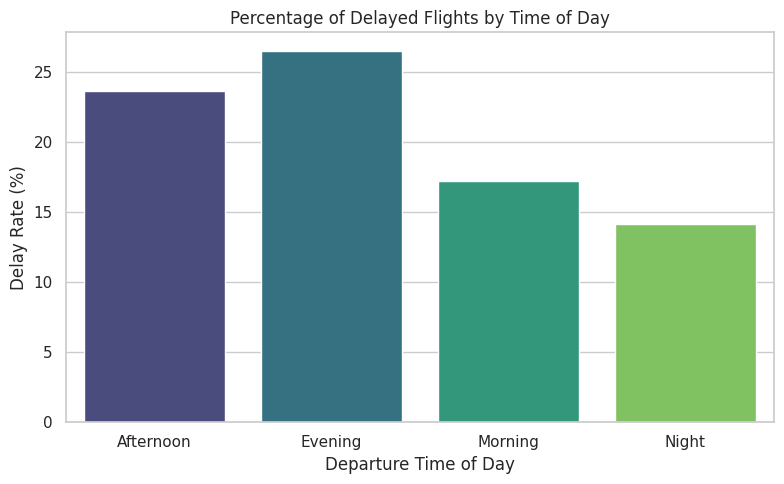

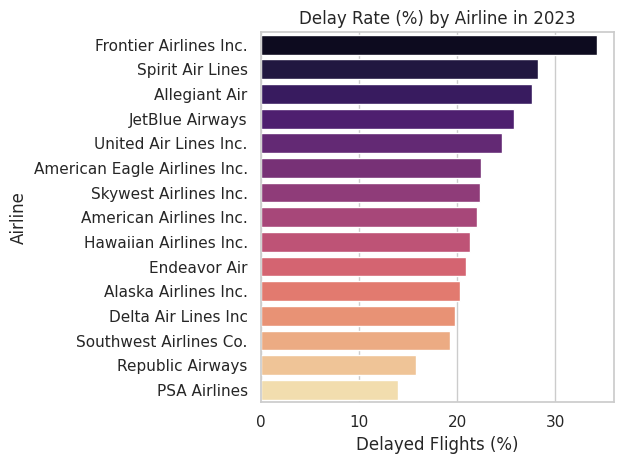


Data Splitting and Encoding Stage
X_train shape: (400000, 10)
X_test shape: (100000, 10)


,Day_Of_Week,Airline,Dep_Airport,DepTime_label,Arr_Airport,Flight_Duration,Distance_type,Manufacturer,Model,Aicraft_age
184624,3,4.0,98.0,2.0,18.0,108,2.0,1.0,5.0,8
124737,6,8.0,18.0,1.0,41.0,138,2.0,3.0,2.0,18
478929,1,14.0,196.0,0.0,88.0,249,1.0,1.0,7.0,23
56117,4,2.0,67.0,0.0,229.0,112,2.0,1.0,5.0,10
403083,3,13.0,106.0,3.0,114.0,172,2.0,0.0,14.0,6


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder

print("Exploratory Data Analysis (EDA)")

plt.figure(figsize=(8, 5))

moment_stats = df_clean.groupby('DepTime_label')['Is_Delayed'].mean().reset_index()
moment_stats['Is_Delayed'] *= 100

sns.barplot(data=moment_stats, x='DepTime_label', y='Is_Delayed', hue='DepTime_label', palette='viridis')
plt.title('Percentage of Delayed Flights by Time of Day')
plt.xlabel('Departure Time of Day')
plt.ylabel('Delay Rate (%)')
plt.tight_layout()
plt.show()

airline_stats = df_clean.groupby('Airline')['Is_Delayed'].mean().reset_index()
airline_stats['Is_Delayed'] *= 100
airline_stats = airline_stats.sort_values(by='Is_Delayed', ascending=False)

sns.barplot(data=airline_stats, x='Is_Delayed', y='Airline', hue='Airline', palette='magma')
plt.title('Delay Rate (%) by Airline in 2023')
plt.xlabel('Delayed Flights (%)')
plt.ylabel('Airline')
plt.tight_layout()
plt.show()

print("\nData Splitting and Encoding Stage")

X = df_clean.drop(columns=['Is_Delayed'])
y = df_clean['Is_Delayed']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()

encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

X_train_encoded = X_train.copy()
X_test_encoded = X_test.copy()

X_train_encoded[categorical_cols] = encoder.fit_transform(X_train[categorical_cols])
X_test_encoded[categorical_cols] = encoder.transform(X_test[categorical_cols])

display(X_train_encoded.head())

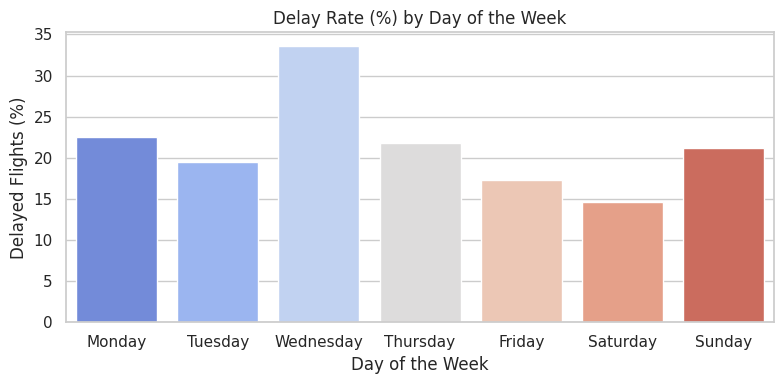

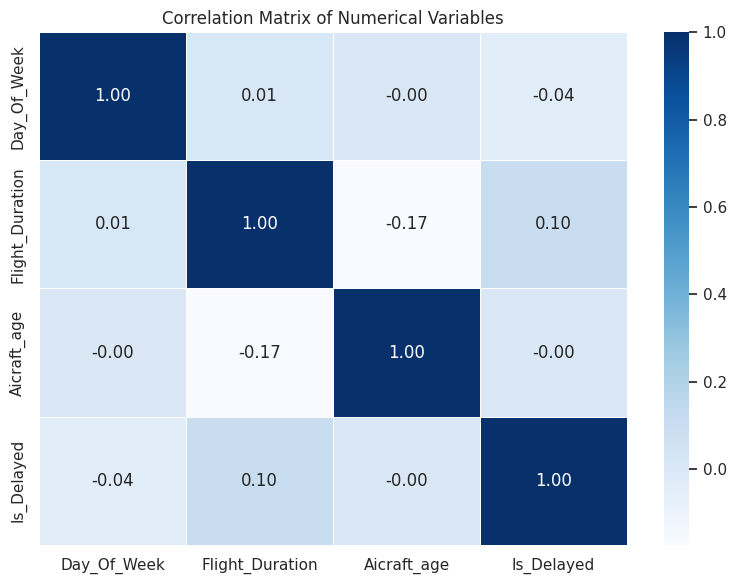

In [10]:
plt.figure(figsize=(8, 4))
day_stats = df_clean.groupby('Day_Of_Week')['Is_Delayed'].mean().reset_index()
day_stats['Is_Delayed'] *= 100

days_map = {1:'Monday', 2:'Tuesday', 3:'Wednesday', 4:'Thursday', 5:'Friday', 6:'Saturday', 7:'Sunday'}
day_stats['Day_Name'] = day_stats['Day_Of_Week'].map(days_map)

sns.barplot(data=day_stats, x='Day_Name', y='Is_Delayed', hue='Day_Name', palette='coolwarm')
plt.title('Delay Rate (%) by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Delayed Flights (%)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))

numeric_df = df_clean.select_dtypes(include=[np.number])

corr_matrix = numeric_df.corr()

sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Numerical Variables')
plt.tight_layout()
plt.show()

Logistic Regression Model

Cross-Validation
ROC-AUC scores per fold: [0.61441302 0.61998107 0.616027   0.61734748 0.61449069]
Mean ROC-AUC from Cross-Validation: 0.6165

Performance Metrics on Test Set:
Accuracy: 0.5953
Precision: 0.2791
Recall (Sensitivity): 0.5587
F1 Score: 0.3723
ROC-AUC Score: 0.6182


<Figure size 600x500 with 0 Axes>

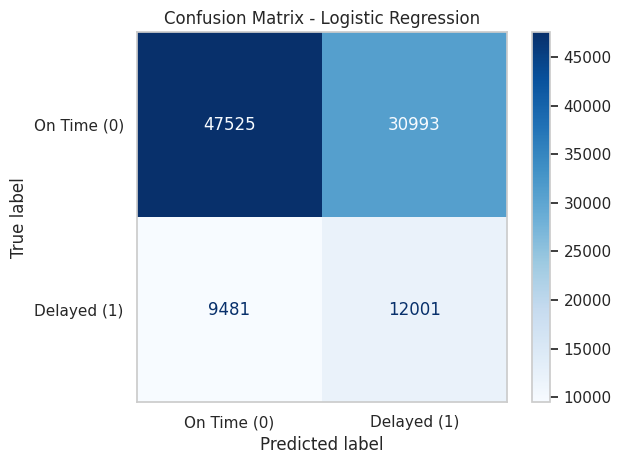

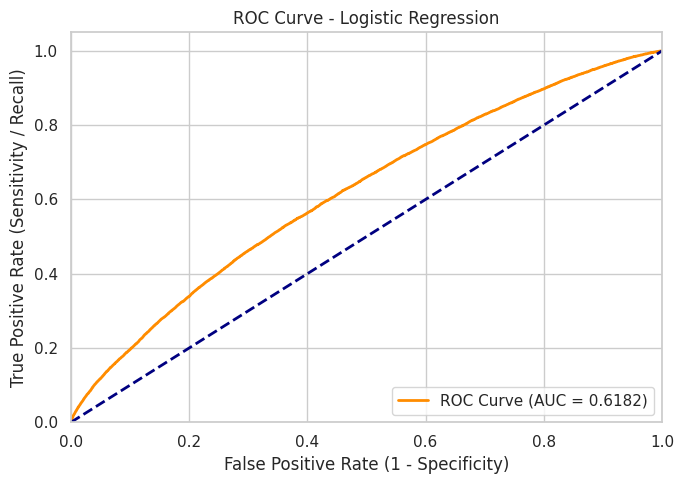

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

print("Logistic Regression Model")
log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

print("\nCross-Validation")
cv_scores = cross_val_score(log_reg, X_train_scaled, y_train, cv=5, scoring='roc_auc')

print(f"ROC-AUC scores per fold: {cv_scores}")
print(f"Mean ROC-AUC from Cross-Validation: {cv_scores.mean():.4f}")

log_reg.fit(X_train_scaled, y_train)
y_pred = log_reg.predict(X_test_scaled)
y_pred_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("\nPerformance Metrics on Test Set:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall (Sensitivity): {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC-AUC Score: {roc_auc:.4f}")

plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['On Time (0)', 'Delayed (1)'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Logistic Regression')
plt.grid(False)
plt.tight_layout()
plt.show()

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc_val = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc_val:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('ROC Curve - Logistic Regression')
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Decision Tree Model
ROC-AUC scores per fold: [0.66459206 0.66883913 0.66882839 0.66719553 0.66865923]
Mean ROC-AUC from Cross-Validation: 0.6676

Performance Metrics on Test Set:
Accuracy: 0.6178
Precision: 0.3097
Recall (Sensitivity): 0.6341
F1 Score: 0.4162
ROC-AUC Score: 0.6729


<Figure size 600x500 with 0 Axes>

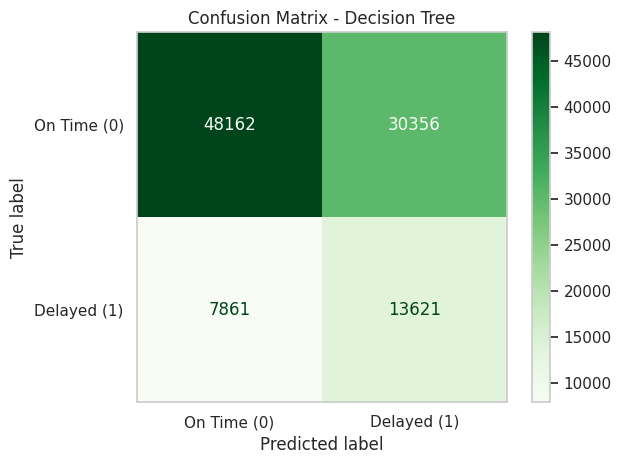

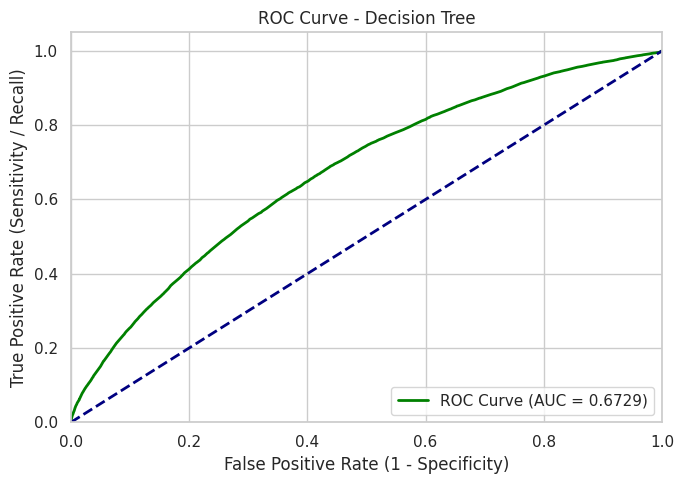

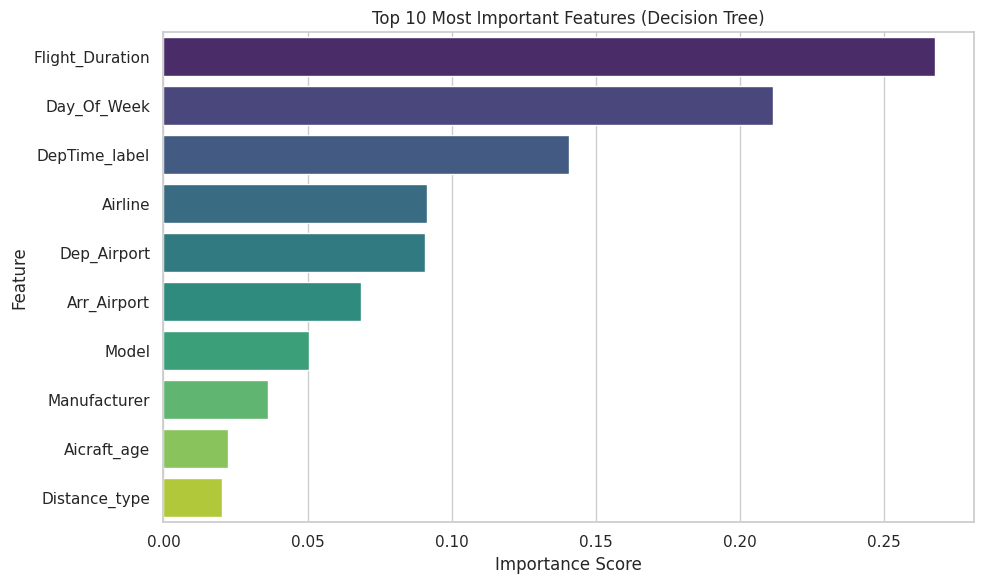

In [11]:
from sklearn.tree import DecisionTreeClassifier

print("Decision Tree Model")

tree_model = DecisionTreeClassifier(max_depth=10, class_weight='balanced', random_state=42)

cv_scores_tree = cross_val_score(tree_model, X_train_scaled, y_train, cv=5, scoring='roc_auc')

print(f"ROC-AUC scores per fold: {cv_scores_tree}")
print(f"Mean ROC-AUC from Cross-Validation: {cv_scores_tree.mean():.4f}")

tree_model.fit(X_train_scaled, y_train)

y_pred_tree = tree_model.predict(X_test_scaled)
y_pred_proba_tree = tree_model.predict_proba(X_test_scaled)[:, 1]

acc_tree = accuracy_score(y_test, y_pred_tree)
prec_tree = precision_score(y_test, y_pred_tree)
rec_tree = recall_score(y_test, y_pred_tree)
f1_tree = f1_score(y_test, y_pred_tree)
roc_auc_tree = roc_auc_score(y_test, y_pred_proba_tree)

print("\nPerformance Metrics on Test Set:")
print(f"Accuracy: {acc_tree:.4f}")
print(f"Precision: {prec_tree:.4f}")
print(f"Recall (Sensitivity): {rec_tree:.4f}")
print(f"F1 Score: {f1_tree:.4f}")
print(f"ROC-AUC Score: {roc_auc_tree:.4f}")

plt.figure(figsize=(6, 5))
cm_tree = confusion_matrix(y_test, y_pred_tree)
disp_tree = ConfusionMatrixDisplay(confusion_matrix=cm_tree, display_labels=['On Time (0)', 'Delayed (1)'])
disp_tree.plot(cmap='Greens', values_format='d')
plt.title('Confusion Matrix - Decision Tree')
plt.grid(False)
plt.tight_layout()
plt.show()

fpr_tree, tpr_tree, _ = roc_curve(y_test, y_pred_proba_tree)
plt.figure(figsize=(7, 5))
plt.plot(fpr_tree, tpr_tree, color='green', lw=2, label=f'ROC Curve (AUC = {roc_auc_tree:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('ROC Curve - Decision Tree')
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

importances = tree_model.feature_importances_
features = X.columns
feat_df = pd.DataFrame({'Feature': features, 'Importance': importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_df.head(10), x='Importance', y='Feature', hue='Feature', palette='viridis')
plt.title('Top 10 Most Important Features (Decision Tree)')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

Random Forest Model
ROC-AUC scores per fold: [0.68587914 0.68671073 0.68601594]
Mean ROC-AUC from Cross-Validation: 0.6862

Performance Metrics on Test Set:
Accuracy: 0.6310
Precision: 0.3206
Recall (Sensitivity): 0.6412
F1 Score: 0.4275
ROC-AUC Score: 0.6885


<Figure size 600x500 with 0 Axes>

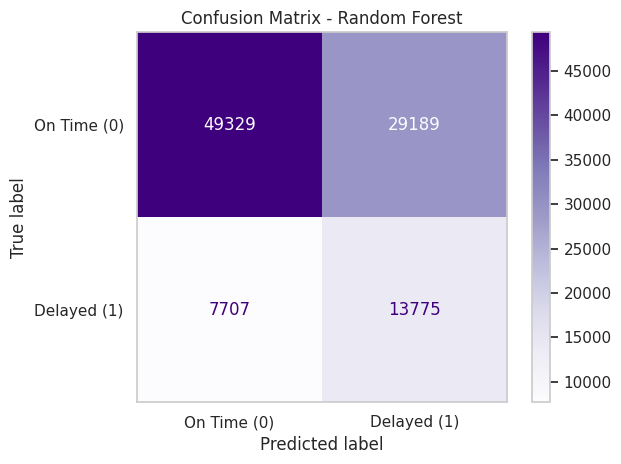

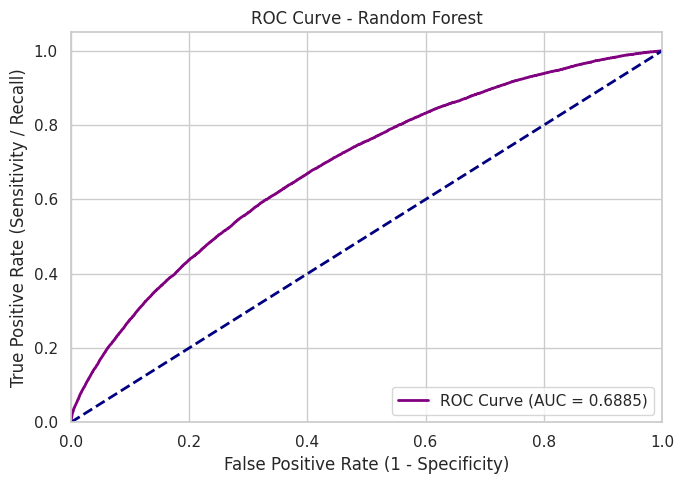

In [ ]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest Model")

rf_model = RandomForestClassifier(n_estimators=50, max_depth=10, class_weight='balanced', n_jobs=-1, random_state=42)

cv_scores_rf = cross_val_score(rf_model, X_train_scaled, y_train, cv=3, scoring='roc_auc')

print(f"ROC-AUC scores per fold: {cv_scores_rf}")
print(f"Mean ROC-AUC from Cross-Validation: {cv_scores_rf.mean():.4f}")

rf_model.fit(X_train_scaled, y_train)

y_pred_rf = rf_model.predict(X_test_scaled)
y_pred_proba_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf)
rec_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_pred_proba_rf)

print("\nPerformance Metrics on Test Set:")
print(f"Accuracy: {acc_rf:.4f}")
print(f"Precision: {prec_rf:.4f}")
print(f"Recall (Sensitivity): {rec_rf:.4f}")
print(f"F1 Score: {f1_rf:.4f}")
print(f"ROC-AUC Score: {roc_auc_rf:.4f}")

plt.figure(figsize=(6, 5))
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['On Time (0)', 'Delayed (1)'])
disp_rf.plot(cmap='Purples', values_format='d')
plt.title('Confusion Matrix - Random Forest')
plt.grid(False)
plt.tight_layout()
plt.show()

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)
plt.figure(figsize=(7, 5))
plt.plot(fpr_rf, tpr_rf, color='purple', lw=2, label=f'ROC Curve (AUC = {roc_auc_rf:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('ROC Curve - Random Forest')
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()